# Predictive maintenance — NASA turbofan engines

A worked notebook following `../data_aai_sose26`: business understanding → data quality → visual EDA → feature engineering → modeling pipelines → evaluation.

## 1. Business understanding
Predict **remaining useful life (RUL), in operating cycles**, from measurements available now. An illustrative maintenance flag means predicted RUL ≤ 30 cycles. This horizon is a teaching assumption, not an approved maintenance policy; no maintenance cost data are supplied.

We start with **FD001**, one operating condition and one fault mode, as described in `data/raw/readme.txt`. FD002–FD004 require separate evaluation. These are simulated engines, not evidence of performance on a real fleet.

### Methods and assumptions
- Training trajectories end at failure: RUL = engine's last training cycle − current cycle.
- Test trajectories stop before failure. Their separate RUL file describes the last observed cycle of each test engine.
- Split by **engine**, never by row. Fit preprocessing only inside each training fold.
- Select models with three-fold grouped cross-validation on training engines. Use uncapped RUL throughout, including final evaluation.
- Rolling features use only the current and previous observations of the same engine.
- Cross-validation averages errors across rows (longer engines contribute more); the official test evaluates one endpoint per engine. These are different evaluation populations.

Course references: `lecture04_missing_values`, `lecture05_outliers`, `lecture06_visual_EDA`, `lecture07_feature_engineering`, `lecture08_modelling_part_1`, `lecture09_modelling_part_2/l09e2-solution-modeling_pipeline.ipynb`, and lectures 10–12 on evaluation and decision thresholds.

## Executed results

Grouped cross-validation selected **Random forest**. On 100 FD001 test-engine endpoints, RMSE is **27.39 cycles** and MAE is **19.51 cycles**. The illustrative 30-cycle maintenance rule has **94.7% precision** and **72.0% recall**. These results describe this simulation benchmark; see the evaluation limits below.

## 2. Setup

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import joblib

ROOT = Path.cwd()
if not (ROOT / 'data/raw/train_FD001.txt').exists():
    ROOT = ROOT / 'nasa-rul'
assert (ROOT / 'data/raw/train_FD001.txt').exists(), 'Run from nasa-rul or its parent.'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
SEED = 42
HORIZON = 30
WINDOW = 5
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'sklearn': sklearn.__version__})

{'python': '3.14.4', 'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1'}


## 3. Load and check the data
One row is one engine at one cycle: two identifiers, three operational settings and 21 sensor measurements (26 columns total). The local README's final sensor numbering has a typo; the file width determines the 21 measurements.

Provenance is in `data/source.json`: these inputs were extracted from an existing archive on 2026-10-14, not freshly verified against a remote download. Check the three selected inputs against that manifest before use.

In [2]:
manifest = json.loads((ROOT / 'data/source.json').read_text())
for name in ['train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt']:
    relative = 'data/raw/' + name
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == manifest['files'][relative]['sha256']

sensors = [f'sensor_{i}' for i in range(1, 22)]
settings = [f'setting_{i}' for i in range(1, 4)]
columns = ['engine_id', 'cycle'] + settings + sensors
def load_data(name):
    frame = pd.read_csv(ROOT / 'data/raw' / name, sep=r'\s+', header=None)
    assert frame.shape[1] == 26
    frame.columns = columns
    assert np.isfinite(frame.to_numpy()).all()
    assert not frame.duplicated(['engine_id', 'cycle']).any()
    assert (frame[['engine_id', 'cycle']] > 0).all().all()
    assert (frame[['engine_id', 'cycle']] % 1 == 0).all().all()
    frame = frame.sort_values(['engine_id', 'cycle']).reset_index(drop=True)
    assert frame.groupby('engine_id')['cycle'].min().eq(1).all()
    assert frame.groupby('engine_id')['cycle'].diff().dropna().eq(1).all()
    return frame

train = load_data('train_FD001.txt')
test = load_data('test_FD001.txt')
train['RUL'] = train.groupby('engine_id')['cycle'].transform('max') - train['cycle']
assert train.groupby('engine_id').tail(1)['RUL'].eq(0).all()
display(train.head())
display(pd.DataFrame({'split': ['train', 'test'], 'rows': [len(train), len(test)],
                      'engines': [train.engine_id.nunique(), test.engine_id.nunique()],
                      'missing_cells': [int(train.isna().sum().sum()), int(test.isna().sum().sum())]}))

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


,split,rows,engines,missing_cells
0,train,20631,100,0
1,test,13096,100,0


## 4. Visual exploration and outliers
Explore training data only. Do not remove extreme sensor values automatically: they may describe degradation. Constant features are removed within each modeling pipeline, not using test statistics.

,lifetime_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


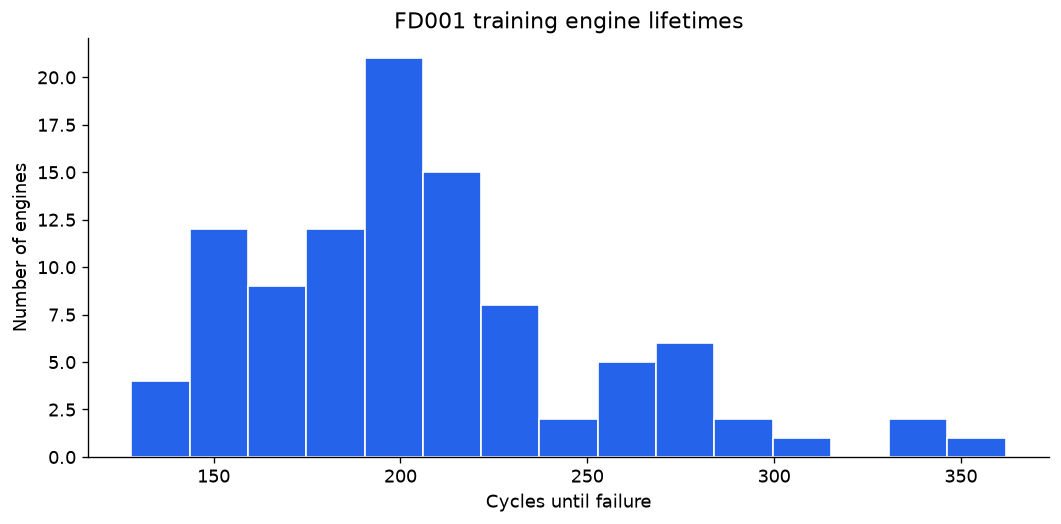

In [3]:
lifetimes = train.groupby('engine_id')['cycle'].max()
display(lifetimes.describe().to_frame('lifetime_cycles'))
fig, ax = plt.subplots()
ax.hist(lifetimes, bins=15, color='#2563eb', edgecolor='white')
ax.set(title='FD001 training engine lifetimes', xlabel='Cycles until failure', ylabel='Number of engines')
fig.tight_layout()
plt.show()

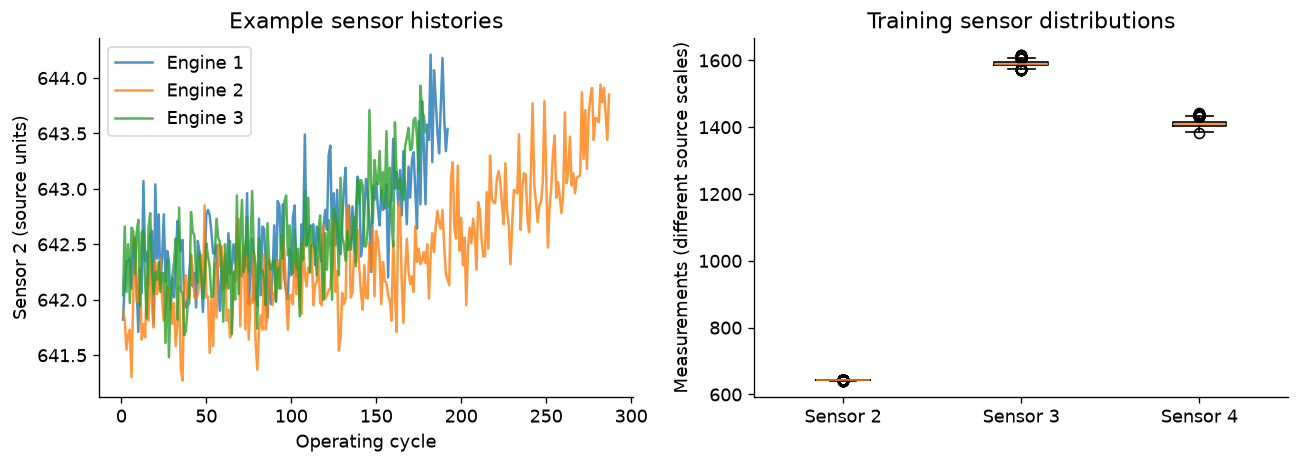

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for engine in [1, 2, 3]:
    sample = train[train.engine_id.eq(engine)]
    axes[0].plot(sample.cycle, sample.sensor_2, label=f'Engine {engine}', alpha=.8)
axes[0].set(title='Example sensor histories', xlabel='Operating cycle', ylabel='Sensor 2 (source units)')
axes[0].legend()
axes[1].boxplot([train[s] for s in ['sensor_2', 'sensor_3', 'sensor_4']], tick_labels=['Sensor 2', 'Sensor 3', 'Sensor 4'])
axes[1].set(title='Training sensor distributions', ylabel='Measurements (different source scales)')
fig.tight_layout()
plt.show()

## 5. Feature engineering
Use cycle, operating settings, sensor readings, trailing five-cycle sensor means and changes since the previous cycle. At the first cycle, change is zero; early rolling means use the available history. Engine ID and failure time are excluded from predictors.

In [5]:
def make_features(frame):
    ordered = frame.sort_values(['engine_id', 'cycle'])
    features = ordered[['cycle'] + settings + sensors].copy()
    groups = ordered.groupby('engine_id', sort=False)
    for sensor in sensors:
        features[sensor + '_mean5'] = groups[sensor].transform(lambda x: x.rolling(WINDOW, min_periods=1).mean())
        features[sensor + '_delta'] = groups[sensor].diff().fillna(0)
    return features.loc[frame.index]

X = make_features(train)
y = train.RUL
groups = train.engine_id
assert 'engine_id' not in X and 'RUL' not in X
assert np.isfinite(X.to_numpy()).all()
# Causality check: truncating an engine must not change earlier features.
prefix = train[train.engine_id.eq(1)].iloc[:25]
pd.testing.assert_frame_equal(make_features(prefix), X.loc[prefix.index])
assert X.loc[train.cycle.eq(1), 'sensor_2_delta'].eq(0).all()
print(f'{X.shape[1]} candidate features; {groups.nunique()} independent engines.')

67 candidate features; 100 independent engines.


## 6. Modeling pipelines and hyperparameter tuning
Compare a mean baseline, scaled Ridge regression and a random forest. Each pipeline learns constant-feature removal from its training fold. Ridge additionally learns scaling there. The small parameter grid keeps this classroom example practical.

`GroupKFold` is the engine-aware replacement for the course's ordinary cross-validation. Select the smallest mean validation RMSE; do not use the official test to choose a model or parameters. Training RMSE helps expose overfitting. Fold standard deviation describes variation, not a confidence interval.

In [6]:
cv = list(GroupKFold(n_splits=3).split(X, y, groups))
for fit_idx, valid_idx in cv:
    assert set(groups.iloc[fit_idx]).isdisjoint(groups.iloc[valid_idx])

candidates = {
    'Mean baseline': (Pipeline([('variance', VarianceThreshold()), ('model', DummyRegressor())]), {}),
    'Ridge': (Pipeline([('variance', VarianceThreshold()), ('scale', StandardScaler()),
                        ('model', Ridge())]), {'model__alpha': [1.0, 100.0, 1000.0]}),
    'Random forest': (Pipeline([('variance', VarianceThreshold()),
                               ('model', RandomForestRegressor(n_estimators=80, random_state=SEED, n_jobs=2))]),
                      {'model__max_depth': [8, None], 'model__min_samples_leaf': [5, 20]})
}
searches, rows = {}, []
for name, (pipeline, grid) in candidates.items():
    search = GridSearchCV(pipeline, grid, cv=cv, scoring='neg_root_mean_squared_error',
                          return_train_score=True, n_jobs=1, error_score='raise')
    search.fit(X, y)
    searches[name] = search
    i = search.best_index_
    rows.append({'model': name, 'train_RMSE': -search.cv_results_['mean_train_score'][i],
                 'CV_RMSE': -search.best_score_, 'fold_SD': search.cv_results_['std_test_score'][i],
                 'parameters': str(search.best_params_)})
comparison = pd.DataFrame(rows).sort_values('CV_RMSE').reset_index(drop=True)
display(comparison.round(3))
winner = comparison.iloc[0]['model']
best_model = searches[winner].best_estimator_
print('Selected using training CV:', winner)

Selected using training CV: Random forest


,model,train_RMSE,CV_RMSE,fold_SD,parameters
0,Random forest,28.650,38.273,0.838,"{'model__max_depth': 8, 'model__min_samples_le..."
1,Ridge,40.087,40.630,1.680,{'model__alpha': 100.0}
2,Mean baseline,68.879,68.882,0.375,{}


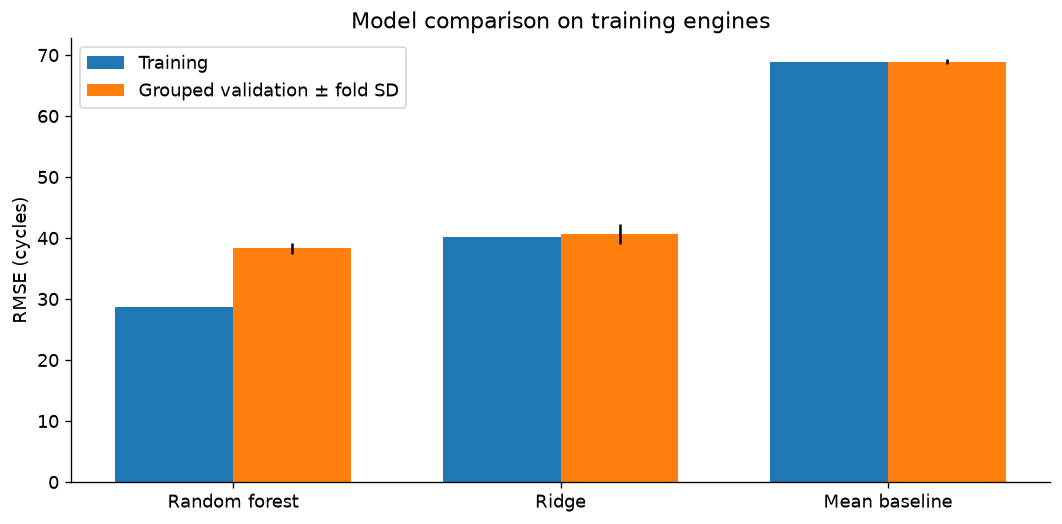

In [7]:
fig, ax = plt.subplots()
positions = np.arange(len(comparison))
ax.bar(positions - .18, comparison.train_RMSE, .36, label='Training')
ax.bar(positions + .18, comparison.CV_RMSE, .36, yerr=comparison.fold_SD, label='Grouped validation ± fold SD')
ax.set(xticks=positions, xticklabels=comparison.model, ylabel='RMSE (cycles)', title='Model comparison on training engines')
ax.legend()
fig.tight_layout()
plt.show()

## 7. Final evaluation on unseen engines
The selected model has been refit on all training engines by `GridSearchCV`. Now read the test labels and evaluate **only the last observed cycle per test engine**. Test and train engine numbers are separate namespaces. Predictions are clipped at zero because negative remaining life is impossible; no upper cap is applied. MAPE is omitted because training RUL includes zero.

In [8]:
truth = pd.read_csv(ROOT / 'data/raw/RUL_FD001.txt', sep=r'\s+', header=None)
assert truth.shape == (test.engine_id.nunique(), 1)
assert np.isfinite(truth.to_numpy()).all() and truth[0].ge(0).all()
endpoints = test.groupby('engine_id', sort=True).tail(1).sort_values('engine_id')
assert endpoints.engine_id.tolist() == list(range(1, len(truth) + 1))
X_test = make_features(test).loc[endpoints.index]
y_test = truth[0].to_numpy()
predicted = np.maximum(0, best_model.predict(X_test))
baseline = np.maximum(0, searches['Mean baseline'].best_estimator_.predict(X_test))
def regression_metrics(actual, pred):
    return {'RMSE_cycles': float(np.sqrt(mean_squared_error(actual, pred))),
            'MAE_cycles': float(mean_absolute_error(actual, pred)), 'R2': float(r2_score(actual, pred)),
            'mean_error_cycles': float(np.mean(pred - actual))}
test_metrics = pd.DataFrame([regression_metrics(y_test, baseline), regression_metrics(y_test, predicted)],
                            index=['Mean baseline', 'Selected model'])
display(test_metrics.round(3))
predictions = pd.DataFrame({'engine_id': endpoints.engine_id.to_numpy(), 'last_cycle': endpoints.cycle.to_numpy(),
                            'actual_RUL': y_test, 'predicted_RUL': predicted})
predictions['error_cycles'] = predicted - y_test
display(predictions.head(10).round(2))

,RMSE_cycles,MAE_cycles,R2,mean_error_cycles
Mean baseline,52.625,40.879,-0.604,32.288
Selected model,27.387,19.506,0.566,10.943


,engine_id,last_cycle,actual_RUL,predicted_RUL,error_cycles
0,1,31,112,180.56,68.56
1,2,49,98,147.03,49.03
2,3,126,69,49.80,-19.20
3,4,106,82,84.59,2.59
4,5,98,91,96.08,5.08
5,6,105,93,95.76,2.76
6,7,160,91,106.98,15.98
7,8,166,95,76.02,-18.98
8,9,55,111,142.67,31.67
9,10,192,96,115.44,19.44


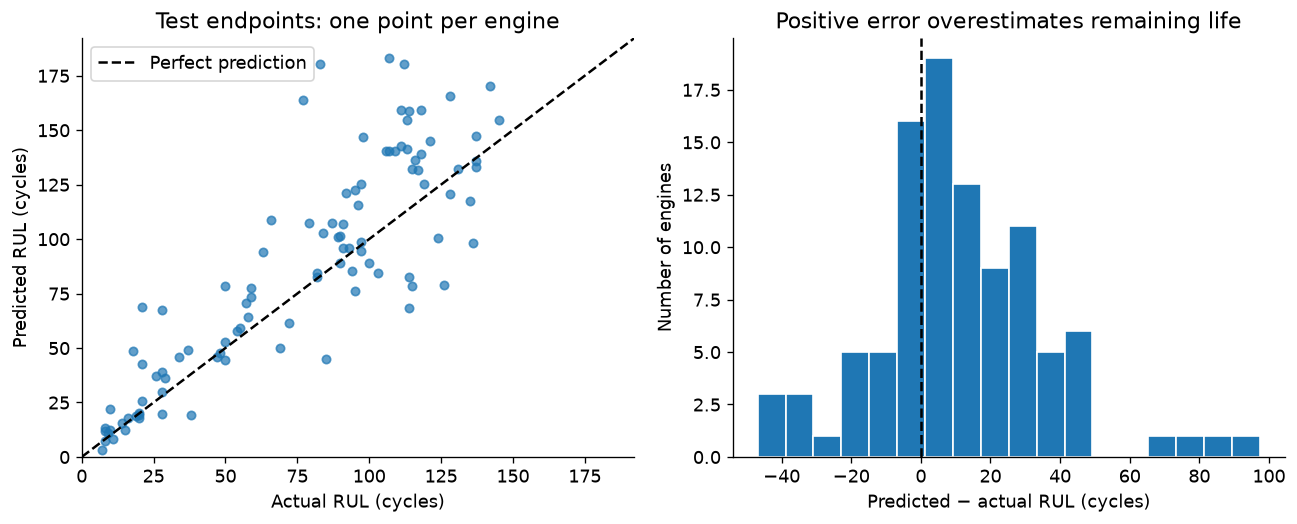

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
limit = max(y_test.max(), predicted.max()) * 1.05
axes[0].scatter(y_test, predicted, alpha=.7, s=25)
axes[0].plot([0, limit], [0, limit], '--', color='black', label='Perfect prediction')
axes[0].set(xlabel='Actual RUL (cycles)', ylabel='Predicted RUL (cycles)', title='Test endpoints: one point per engine', xlim=(0, limit), ylim=(0, limit))
axes[0].legend()
axes[1].hist(predicted - y_test, bins=18, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted − actual RUL (cycles)', ylabel='Number of engines', title='Positive error overestimates remaining life')
fig.tight_layout()
plt.show()

## 8. Translate predictions into a maintenance flag
Flag an engine when predicted RUL ≤ 30 cycles. Ground truth is actual RUL ≤ 30. A false negative misses an engine within this horizon; a false positive requests early inspection. This is a fixed illustrative rule, not a tuned probability threshold. Precision and recall are measured on the test endpoints, not on every cycle or complete maintenance events. No cost savings or operational safety claims follow from this benchmark.

,value
horizon_cycles,30.000000
actual_positive_engines,25.000000
predicted_positive_engines,19.000000
precision,0.947368
recall,0.720000
F1,0.818182


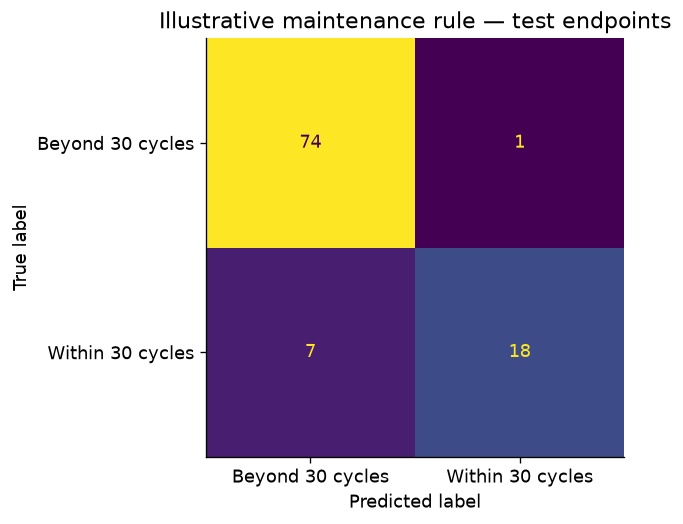

In [10]:
actual_alert = y_test <= HORIZON
predicted_alert = predicted <= HORIZON
alert_metrics = {'horizon_cycles': HORIZON, 'actual_positive_engines': int(actual_alert.sum()),
                 'predicted_positive_engines': int(predicted_alert.sum()),
                 'precision': float(precision_score(actual_alert, predicted_alert, zero_division=0)),
                 'recall': float(recall_score(actual_alert, predicted_alert, zero_division=0)),
                 'F1': float(f1_score(actual_alert, predicted_alert, zero_division=0))}
display(pd.Series(alert_metrics).to_frame('value'))
ConfusionMatrixDisplay.from_predictions(actual_alert, predicted_alert, labels=[False, True],
                                       display_labels=['Beyond 30 cycles', 'Within 30 cycles'], colorbar=False)
plt.title('Illustrative maintenance rule — test endpoints')
plt.tight_layout()
plt.show()
predictions['maintenance_flag'] = predicted_alert

## 9. Save results and interpret

In [11]:
comparison.to_csv(OUT / 'model_comparison.csv', index=False)
predictions.to_csv(OUT / 'test_predictions_FD001.csv', index=False)
test_metrics.to_csv(OUT / 'test_metrics.csv')
results = {'dataset': 'FD001', 'selected_model': winner,
           'best_parameters': searches[winner].best_params_,
           'test': regression_metrics(y_test, predicted), 'maintenance': alert_metrics,
           'seed': SEED, 'window': WINDOW, 'features': list(X.columns),
           'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                        'pandas': pd.__version__, 'numpy': np.__version__}}
(OUT / 'results.json').write_text(json.dumps(results, indent=2))
joblib.dump({'pipeline': best_model, 'features': list(X.columns), 'window': WINDOW,
             'horizon': HORIZON, 'dataset': 'FD001'}, OUT / 'rul_model.joblib')
print(f"{winner}: test RMSE {results['test']['RMSE_cycles']:.2f} cycles; MAE {results['test']['MAE_cycles']:.2f} cycles.")
print(f"30-cycle rule: precision {alert_metrics['precision']:.1%}; recall {alert_metrics['recall']:.1%}.")
print('Saved results and fitted model to', OUT)

Random forest: test RMSE 27.39 cycles; MAE 19.51 cycles.
30-cycle rule: precision 94.7%; recall 72.0%.
Saved results and fitted model to /home/alex/projects/nasa-rul/outputs


### Takeaways and next steps
Use the executed comparison and test metrics above to judge improvement over the mean baseline. A gap between training and grouped validation errors suggests overfitting. Test errors above zero are particularly relevant because they overestimate remaining life.

This tutorial does not establish deployment readiness. The test population has one truncated endpoint per engine, while tuning uses all cycles. For a stronger follow-up, validate at simulated observation endpoints on held-out training engines, examine engine-level uncertainty, and choose an alert rule using a specified maintenance cost matrix and validation data. Evaluate FD002–FD004 separately, accounting for their operating conditions and fault modes. Do not repeatedly tune against FD001 test results.

For new histories, apply the same `make_features` function to complete available histories, select the latest row per engine, and call the saved pipeline with the saved feature order. The model artifact alone does not construct rolling features. Load joblib files only from trusted sources.